# 3. Replicate Figure 1 using USAJOBS

Use the paper's released code to construct rankings, compare them with observed occupational transitions, and draw the RN pipeline and validation figure using a different posting corpus.

**Run Notebook 2 first.** This notebook reads its occupation-task vectors and scores. All three notebooks use the assembled USAJOBS corpus; the RN case illustrates an all-occupation model. The default RCA reference now uses retained links, matching the paper. The earlier USAJOBS specification is retained as an explicitly optional sensitivity in Notebook 2.

The package includes O*NET published related occupations, the paper's candidate mappings, and aggregate benchmark outcomes. It contains no NLx postings or survey person records. We also run a control that reproduces the paper's published benchmark summaries from its released NLx score matrix. That control establishes code agreement, not equality of USAJOBS and NLx estimates.

Source differences: all supplied USAJOBS postings have weight 1; support is at least five postings per link; the supplied NLx occupation–task exclusion list is applied, while unreviewed links remain. This transfers pair exclusions; it is not a new review of USAJOBS postings. The reference population comprises valid USAJOBS occupations. Benchmark eligibility intersects the paper's eligible specialties with USAJOBS occupations having at least 200 postings and a nonempty vector. Candidate memberships and exclusions are exported.

In [1]:
from pathlib import Path
import sys,json,hashlib,importlib.util
import numpy as np
import pandas as pd
from scipy import sparse
from IPython.display import display,Image
P=Path.cwd(); PAPER=P/'paper_code_and_inputs'; OUT=P/'results/figure2_usajobs'
OUT.mkdir(parents=True,exist_ok=True)
# Verify the included paper code/data subset. No frozen paper assertions are removed.
for name,h in json.loads((PAPER/'included_files_sha256.json').read_text()).items():
    assert hashlib.sha256((PAPER/name).read_bytes()).hexdigest()==h,name
sys.path.insert(0,str(PAPER));sys.path.insert(0,str(PAPER/'figure'))
import reproduce as paper
from replicate import calculate,read_inputs,verify_summary
from public_figure_from_excel import read as read_figure_workbook
from figure_rendering import render as render_paper
print('Verified unchanged paper functions and released inputs.')

Verified unchanged paper functions and released inputs.


## Control: recover the paper's estimates

Use the original `rank_groups` and `calculate` functions. O*NET's directed ranks become scores `(21 − rank)/20`, with zero for an unlisted pair. Group scores average every specialty-pair score. Rankings exclude self matches and use only positive scores; ties use rounded scores and ascending codes.

The expected rankings and summary are checked only after recalculating them. These are NLx paper results, separate from the USAJOBS results below.

In [2]:
expected,observed,origins=read_inputs(PAPER/'benchmark_inputs')
with np.load(PAPER/'relatedness_scores.npz',allow_pickle=False) as z:
    paper_codes=z['codes'].astype(str);paper_scores=z['similarity']
relations=pd.read_csv(PAPER/'onet_published_relations.csv')
onet_codes=sorted(set(paper_codes)|set(relations['O*NET-SOC Code'])|set(relations['Related O*NET-SOC Code']))
onet_index={c:i for i,c in enumerate(onet_codes)}
onet_scores=np.zeros((len(onet_codes),len(onet_codes)))
for a,b,r in relations[['O*NET-SOC Code','Related O*NET-SOC Code','Index']].itertuples(index=False,name=None):
    onet_scores[onet_index[a],onet_index[b]]=(21-r)/20
paper_parts=[]
for ds,g in origins.groupby('dataset',sort=False):
    groups=paper.groups_for(ds)
    for model,cs,mat in [('task',paper_codes,paper_scores),('onet_published',onet_codes,onet_scores)]:
        ranks=paper.rank_groups(cs,mat,groups,g.origin.tolist())
        ranks['dataset']=ds;ranks['model']=model;paper_parts.append(ranks)
paper_ranks=pd.concat(paper_parts,ignore_index=True)
keys=['dataset','origin','model','rank']
pd.testing.assert_frame_equal(paper_ranks.sort_values(keys)[keys+['destination']].reset_index(drop=True),
 expected.sort_values(keys)[keys+['destination']].reset_index(drop=True))
_,paper_summary,_=calculate(paper_ranks.drop(columns='score'),observed,origins)
verify_summary(paper_summary,pd.read_csv(PAPER/'benchmark_inputs/expected_summary.csv'))
print('PASS: paper rankings and all six benchmark summaries reproduced.')
display(paper_summary[paper_summary['mode'].eq('equal_length')][['dataset','origins','task','onet_published','share_more']])

PASS: paper rankings and all six benchmark summaries reproduced.


,dataset,origins,task,onet_published,share_more
0,SST,604,0.156774,0.112166,0.773179
1,Emsi,429,0.274126,0.177506,0.743590
2,CPS_SIPP,109,0.211483,0.192192,0.642202
3,NLSY97_PSID_3y,77,0.147918,0.123086,0.675325
4,NLSY97_PSID_5y,76,0.130952,0.105499,0.684211
5,NLSY97_PSID_10y,65,0.104697,0.082600,0.676923


## Use the USAJOBS model and declare comparison coverage

Only common eligible destinations are ranked for both models. When a paper group contains unavailable USAJOBS specialties, its score averages the remaining eligible specialties; the exported mapping identifies every change. We preserve the original outcome denominators, including mass on destinations outside this candidate set. No candidates are chosen using transition outcomes.

In [3]:
run=json.loads((P/'results/similarity_run.json').read_text())
assert run.get('reference_stage')=='retained', 'Run Notebook 2 with REFERENCE_STAGE="retained" for the Figure 2 replication.'
with np.load(P/'results/task_similarity.npz',allow_pickle=False) as z:
    codes=z['codes'].astype(str);scores=z['similarity']
v=sparse.load_npz(P/'results/task_vectors.npz')
counts_source=P/'results' if (P/'results/totals8.parquet').exists() else P/'data'
totals=pd.read_parquet(counts_source/'totals8.parquet').set_index('code')
tasks=pd.read_csv(P/'data/tasks.csv');task_ids=sorted(tasks.task_id.unique())
assert v.shape==(len(codes),len(task_ids))
# Independently reconstruct vectors with the unchanged paper helper.
spec=importlib.util.spec_from_file_location('paper_metrics',PAPER/'production_source/analysis/occupation_relatedness/metrics.py')
metrics=importlib.util.module_from_spec(spec);spec.loader.exec_module(metrics)
raw_inc=pd.read_parquet(counts_source/'incidence8.parquet')
retained=raw_inc[raw_inc.code.isin(codes)&raw_inc.task_id.isin(task_ids)&raw_inc.n_documents.ge(5)]
exclusions=pd.read_csv(P/'data/occupation_task_exclusions.csv')
retained=retained.merge(exclusions[['code','task_id']].assign(exclude=True),on=['code','task_id'],how='left',validate='one_to_one')
retained=retained.loc[~retained.exclude.eq(True)]
M=sparse.csr_matrix((retained.weight,(pd.Index(codes).get_indexer(retained.code),pd.Index(task_ids).get_indexer(retained.task_id))),shape=v.shape)
mass=np.asarray(M.sum(0)).ravel();reference=mass/mass.sum()
_,paper_vectors=metrics.representation(M,np.divide(1,reference,out=np.zeros_like(reference),where=reference>0))
np.testing.assert_allclose(metrics.cosine_matrix(paper_vectors),scores,atol=1e-12,rtol=1e-12)
print('PASS: Notebook 2 scores match the unchanged paper representation function.')
titles=pd.read_csv(P/'data/occupations.csv').set_index('O*NET-SOC Code').Title
paper_eligible=pd.read_csv(PAPER/'comparison_universe.csv')
paper_eligible=set(paper_eligible.loc[paper_eligible.common_eligible,'occupational_code'])
nonempty=np.asarray(v.multiply(v).sum(1)).ravel()>0
eligible={c for i,c in enumerate(codes) if c in paper_eligible and totals.loc[c,'n_documents']>=200 and nonempty[i]}
print('USAJOBS construction occupations:',len(codes),'Common eligible specialties:',len(eligible))
parts=[];origin_parts=[];members=[];coverage=[];group_sets={}
for ds,g in origins.groupby('dataset',sort=False):
    original=paper.groups_for(ds)
    groups={k:[c for c in cs if c in eligible] for k,cs in original.items()}
    groups={k:cs for k,cs in groups.items() if cs};group_sets[ds]=groups
    allowed=g[g.origin.isin(groups)].copy();origin_parts.append(allowed)
    coverage.append({'dataset':ds,'paper_origins':len(g),'usajobs_origins':len(allowed),'candidate_groups':len(groups),
                     'groups_with_changed_membership':sum(groups[k]!=original[k] for k in groups)})
    for k,cs in original.items():
        members.append({'dataset':ds,'group':k,'paper_specialties':';'.join(cs),'usajobs_specialties':';'.join(groups.get(k,[]))})
    for model,cs,mat in [('task',codes,scores),('onet_published',onet_codes,onet_scores)]:
        r=paper.rank_groups(cs,mat,groups,allowed.origin.tolist());r['dataset']=ds;r['model']=model;parts.append(r)
ranks=pd.concat(parts,ignore_index=True);usa_origins=pd.concat(origin_parts,ignore_index=True)
usa_observed=observed.merge(usa_origins[['dataset','origin']],on=['dataset','origin'],validate='many_to_one')
pd.DataFrame(members).to_csv(OUT/'candidate_memberships.csv',index=False)
pd.DataFrame(coverage).to_csv(OUT/'coverage.csv',index=False)
display(pd.DataFrame(coverage))

PASS: Notebook 2 scores match the unchanged paper representation function.
USAJOBS construction occupations: 994 Common eligible specialties: 614


,dataset,paper_origins,usajobs_origins,candidate_groups,groups_with_changed_membership
0,SST,604,428,445,8
1,Emsi,429,261,474,18
2,CPS_SIPP,109,85,295,28
3,NLSY97_PSID_3y,77,58,228,24
4,NLSY97_PSID_5y,76,56,228,24
5,NLSY97_PSID_10y,65,48,228,24


## Apply the same benchmark arithmetic

For each origin, compare the first `min(20, task-list length, O*NET-list length)` unique destinations from each model. SST captures released transition shares; EMSI recovers members of its original top twenty (each worth 1/20); surveys capture pooled outcome weight using original denominators. Means give origins equal weight. The share with greater recovery includes ties in its denominator. See the included paper README for survey pooling and source limitations.

These are an application of the paper's evaluation rules to USAJOBS, not a new held-out validation design.

In [4]:
by,summary,audit=calculate(ranks.drop(columns='score'),usa_observed,usa_origins)
equal=summary[summary['mode'].eq('equal_length')].copy()
display(equal[['dataset','origins','mean_k','task','onet_published','more','ties','share_more']])
for name,frame in [('rankings',ranks),('by_origin',by),('summary',summary),('recommendation_audit',audit)]:
    frame.to_csv(OUT/(name+'.csv'),index=False)
# Verify every retained comparison uses exactly the same number of recommendations.
selected=audit[audit.selected_equal]
lengths=selected.groupby(['dataset','origin','model']).size().unstack(fill_value=0)
assert (lengths.task==lengths.onet_published).all()
assert (by.loc[by['mode'].eq('equal_length'),'matched_k']<=20).all()
print('PASS: equal recommendation counts in every comparison.')
# Count each SST/EMSI SOC6 once; distinguish opposite directions.
unique_rows=[]
for r in by[by['mode'].eq('equal_length') & by.included & by.dataset.isin(['SST','Emsi'])].itertuples():
    socs={code[:7] for code in group_sets[r.dataset][r.origin]}
    assert len(socs)==1
    unique_rows.append({'soc6':next(iter(socs)),'difference':r.difference})
unique_frame=pd.DataFrame(unique_rows)
unique_total={'Posting tasks':0,'Equal':0,'O*NET':0,'Mixed':0,'total':unique_frame.soc6.nunique()}
for _,g in unique_frame.groupby('soc6'):
    up=(g.difference>1e-12).any();down=(g.difference < -1e-12).any()
    key='Mixed' if up and down else 'Posting tasks' if up else 'O*NET' if down else 'Equal'
    unique_total[key]+=1
(OUT/'unique_total.json').write_text(json.dumps(unique_total,indent=2))

# Same aggregation diagnostic as Figure 1, evaluated on USAJOBS only.
from aggregation_comparison import compare
representation_summary=compare(M,codes,task_ids,group_sets,usa_observed,by,metrics,
    P/'data/production_task_dwa_bridge.csv',OUT)
display(representation_summary[representation_summary.dataset.isin(['SST','Emsi'])])


,dataset,origins,mean_k,task,onet_published,more,ties,share_more
0,SST,428,11.542056,0.124028,0.113794,251,2,0.586449
1,Emsi,261,13.045977,0.191762,0.188506,110,58,0.421456
2,CPS_SIPP,85,10.764706,0.152933,0.174836,35,3,0.411765
3,NLSY97_PSID_3y,58,8.948276,0.093594,0.106298,26,5,0.448276
4,NLSY97_PSID_5y,56,8.785714,0.087490,0.089396,25,4,0.446429
5,NLSY97_PSID_10y,48,9.000000,0.072911,0.071600,24,3,0.500000


PASS: equal recommendation counts in every comparison.


,dataset,model,mean,n
4,Emsi,dwa,0.190230,261
5,Emsi,mapped_tasks,0.191762,261
6,Emsi,onet,0.188506,261
7,Emsi,task,0.191762,261
20,SST,dwa,0.120895,428
21,SST,mapped_tasks,0.124028,428
22,SST,onet,0.113794,428
23,SST,task,0.124028,428


## Assemble the RN example from USAJOBS

The RN and manager groups use the **same eligible specialties as the benchmark's SOC mapping**. Shared-task contributions average coordinate products across all specialty pairs, so their sum equals the group similarity. The five largest contributions are shown. The illustration is selected for continuity with the paper, not because it maximizes USAJOBS performance.

Panel F uses all valid, pre-support-filter USAJOBS task incidences with unit posting weights. It checks whether the assigned occupation and the O*NET home share two, four or six SOC digits. The profiles used for similarity subsequently apply minimum support and the supplied occupation–task exclusions; Panel F precedes those filters.

In [5]:
origin='29-1141';destination='11-9111';groups=group_sets['SST'];ix={c:i for i,c in enumerate(codes)}
assert origin in groups and destination in groups
A=[ix[c] for c in groups[origin]];B=[ix[c] for c in groups[destination]]
mean_a=np.asarray(v[A].mean(0)).ravel();mean_b=np.asarray(v[B].mean(0)).ravel()
contributions=mean_a*mean_b;pair_score=float(scores[np.ix_(A,B)].mean())
np.testing.assert_allclose(contributions.sum(),pair_score,atol=1e-12)
canon=set(tasks.loc[tasks.occ8.str[:7].eq(origin),'task_id'])
shared=pd.DataFrame({'task_id':task_ids,'similarity_contribution':contributions})
shared=shared[shared.similarity_contribution>0].sort_values(['similarity_contribution','task_id'],ascending=[False,True])
shared['task_text']=shared.task_id.map(tasks.set_index('task_id').task_text)
shared['share_of_pair_similarity']=shared.similarity_contribution/pair_score
shared['canonical_in_focal']=shared.task_id.isin(canon)
shared.to_csv(OUT/'rn_manager_all_shared_tasks.csv',index=False)
# Fresh SOC-group top-ten lists; no stale paper badges or scores.
rows=[]
for method,cs,mat in [('task',codes,scores),('onet_published',onet_codes,onet_scores)]:
    top=paper.rank_groups(cs,mat,groups,[origin]).head(10)
    for r in top.itertuples():
        rows.append({'method':method,'rank':r.rank,'destination':r.destination,
         'display_destination':r.destination,'destination_title':titles[groups[r.destination][0]],'score':r.score})
lists=pd.DataFrame(rows)
for ds,col in [('SST','sst_rank'),('Emsi','emsi_rank')]:
    truth=observed[observed.dataset.eq(ds)&observed.origin.eq(origin)].sort_values(['mass','destination'],ascending=[False,True]).head(20)
    truth_rank={d:i for i,d in enumerate(truth.destination,1)}
    lists[col]=lists.destination.map(truth_rank)
# EMSI released outcomes are equal-mass top-20 memberships, not original ranks.
# Display membership only: omit numbered badges rather than invent an ordering.
lists['emsi_rank']=np.nan
lists['cps_sipp_rank']=np.nan
inc=pd.read_parquet(counts_source/'incidence8.parquet')
inc=inc[inc.code.isin(codes)&inc.task_id.isin(task_ids)].copy()
home=inc.task_id.map(tasks.set_index('task_id').occ8)
allocation={f'SOC {level}':float(inc.loc[inc.code.str[:width].ne(home.str[:width]),'weight'].sum()/inc.weight.sum())
 for level,width in [(6,7),(4,5),(2,2)]}
selected=lists[lists.method.eq('task')&lists.destination.eq(destination)]
if selected.empty:
    # Still explain the selected pair without drawing an arrow to a false top-ten rank.
    chosen=pd.Series({'destination':destination,'rank':np.nan})
else: chosen=selected.iloc[0]
c={'code':origin,'display_code':origin,'title':'Registered Nurses','lists':lists,
 'shared_tasks':shared.head(5),'shared_task_count':len(shared),'pair_similarity':pair_score,
 'selected':chosen,'onet_selected':lists[lists.method.eq('onet_published')].iloc[0],
 'validation':pd.DataFrame(columns=['benchmark','population','method','value','origins','origin','status']),
 'equal_length_summary':equal.to_dict('records'),'task_allocation_outside_share':allocation,
 'source_heading':'USAJOBS · Pipeline and validation',
 'source_note_lines':['Saved JAAT assignments',f'{int(totals.loc[groups[origin],"n_documents"].sum()):,} RN postings',
                      f'{len(groups[origin])} eligible RN specialties','Full assembled corpus','2017–March 2026','All postings: weight 1',
                      'Square-root RCA','Cosine similarity'],
 'validation_axis_max':max(.30,float(equal[['task','onet_published']].max().max())*1.35)}
print('RN–manager benchmark-group similarity:',pair_score,'Shared tasks:',len(shared))
display(lists);display(shared.head(5));print('Outside assignment:',allocation)
c['unique_total']=unique_total
lists.to_csv(OUT/'figure2_usajobs_top10.csv',index=False)
shared.head(5).to_csv(OUT/'figure2_usajobs_shared_tasks.csv',index=False)
equal.to_csv(OUT/'figure2_usajobs_equal_length_summary.csv',index=False)

c['representation_summary']=representation_summary.to_dict('records')

# Use all available task-to-DWA links; allocate each pre-filter incidence equally.
from activity_assignment import calculate as activity_allocation
dwa_alignment=activity_allocation(inc,pd.read_csv(P/"data/onet_27_2_task_dwa_assignments.csv"))
dwa_alignment.to_csv(OUT/"dwa_alignment_summary.csv",index=False)
c["dwa_allocation_outside_share"]={f"SOC {int(r.soc_digits)}":r.dwa_outside_share for r in dwa_alignment.itertuples()}


RN–manager benchmark-group similarity: 0.37713186041846386 Shared tasks: 1711


,method,rank,destination,display_destination,destination_title,score,sst_rank,emsi_rank,cps_sipp_rank
0,task,1,29-1171,29-1171,Nurse Practitioners,0.419140,4.0,NaN,NaN
1,task,2,29-2061,29-2061,Licensed Practical and Licensed Vocational Nurses,0.418660,7.0,NaN,NaN
2,task,3,11-9111,11-9111,Medical and Health Services Managers,0.377132,1.0,NaN,NaN
3,task,4,25-1072,25-1072,"Nursing Instructors and Teachers, Postsecondary",0.352745,10.0,NaN,NaN
4,task,5,31-2012,31-2012,Occupational Therapy Aides,0.351477,NaN,NaN,NaN
5,task,6,31-1014,31-1014,Nursing Assistants,0.347800,15.0,NaN,NaN
6,task,7,31-1013,31-1013,Psychiatric Aides,0.304546,NaN,NaN,NaN
7,task,8,29-1062,29-1062,Family Medicine Physicians,0.264198,NaN,NaN,NaN
8,task,9,31-9092,31-9092,Medical Assistants,0.258207,NaN,NaN,NaN
9,task,10,39-9041,39-9041,Residential Advisors,0.232407,NaN,NaN,NaN


,task_id,similarity_contribution,task_text,share_of_pair_similarity,canonical_in_focal
13939,18008,0.003128,"Develop, implement, or evaluate standards of n...",0.008293,True
12370,16035,0.002906,Maintain knowledge of current events and trend...,0.007705,False
15880,20418,0.002850,"Lead nursing department implementation of, or ...",0.007558,True
15714,20226,0.002850,"Write articles, white papers, or reports to sh...",0.007556,False
14182,18353,0.002807,Supervise and monitor unit nursing staff.,0.007442,True


Outside assignment: {'SOC 6': 0.9563313671894602, 'SOC 4': 0.8911319248076933, 'SOC 2': 0.7734962732746513}


Figure 2 uses the same three-task, five-occupation layout as manuscript Figure 1, with aligned ranks in panels C and D. Panels G–H display SST and EMSI plus their unique-occupation total; all six comparisons are saved in the result tables. Numerical inputs come from USAJOBS: task contributions, source counts, similarity, allocation and benchmark recovery. Only verified SST ranks appear as badges. The paper control is rendered separately from its public workbook. The CSV exports retain the fuller diagnostic lists; the figure displays three tasks and five destinations.


Panel G compares task-level profiles with profiles that aggregate posting tasks into detailed work activities. The SI reports the additional representation comparisons.


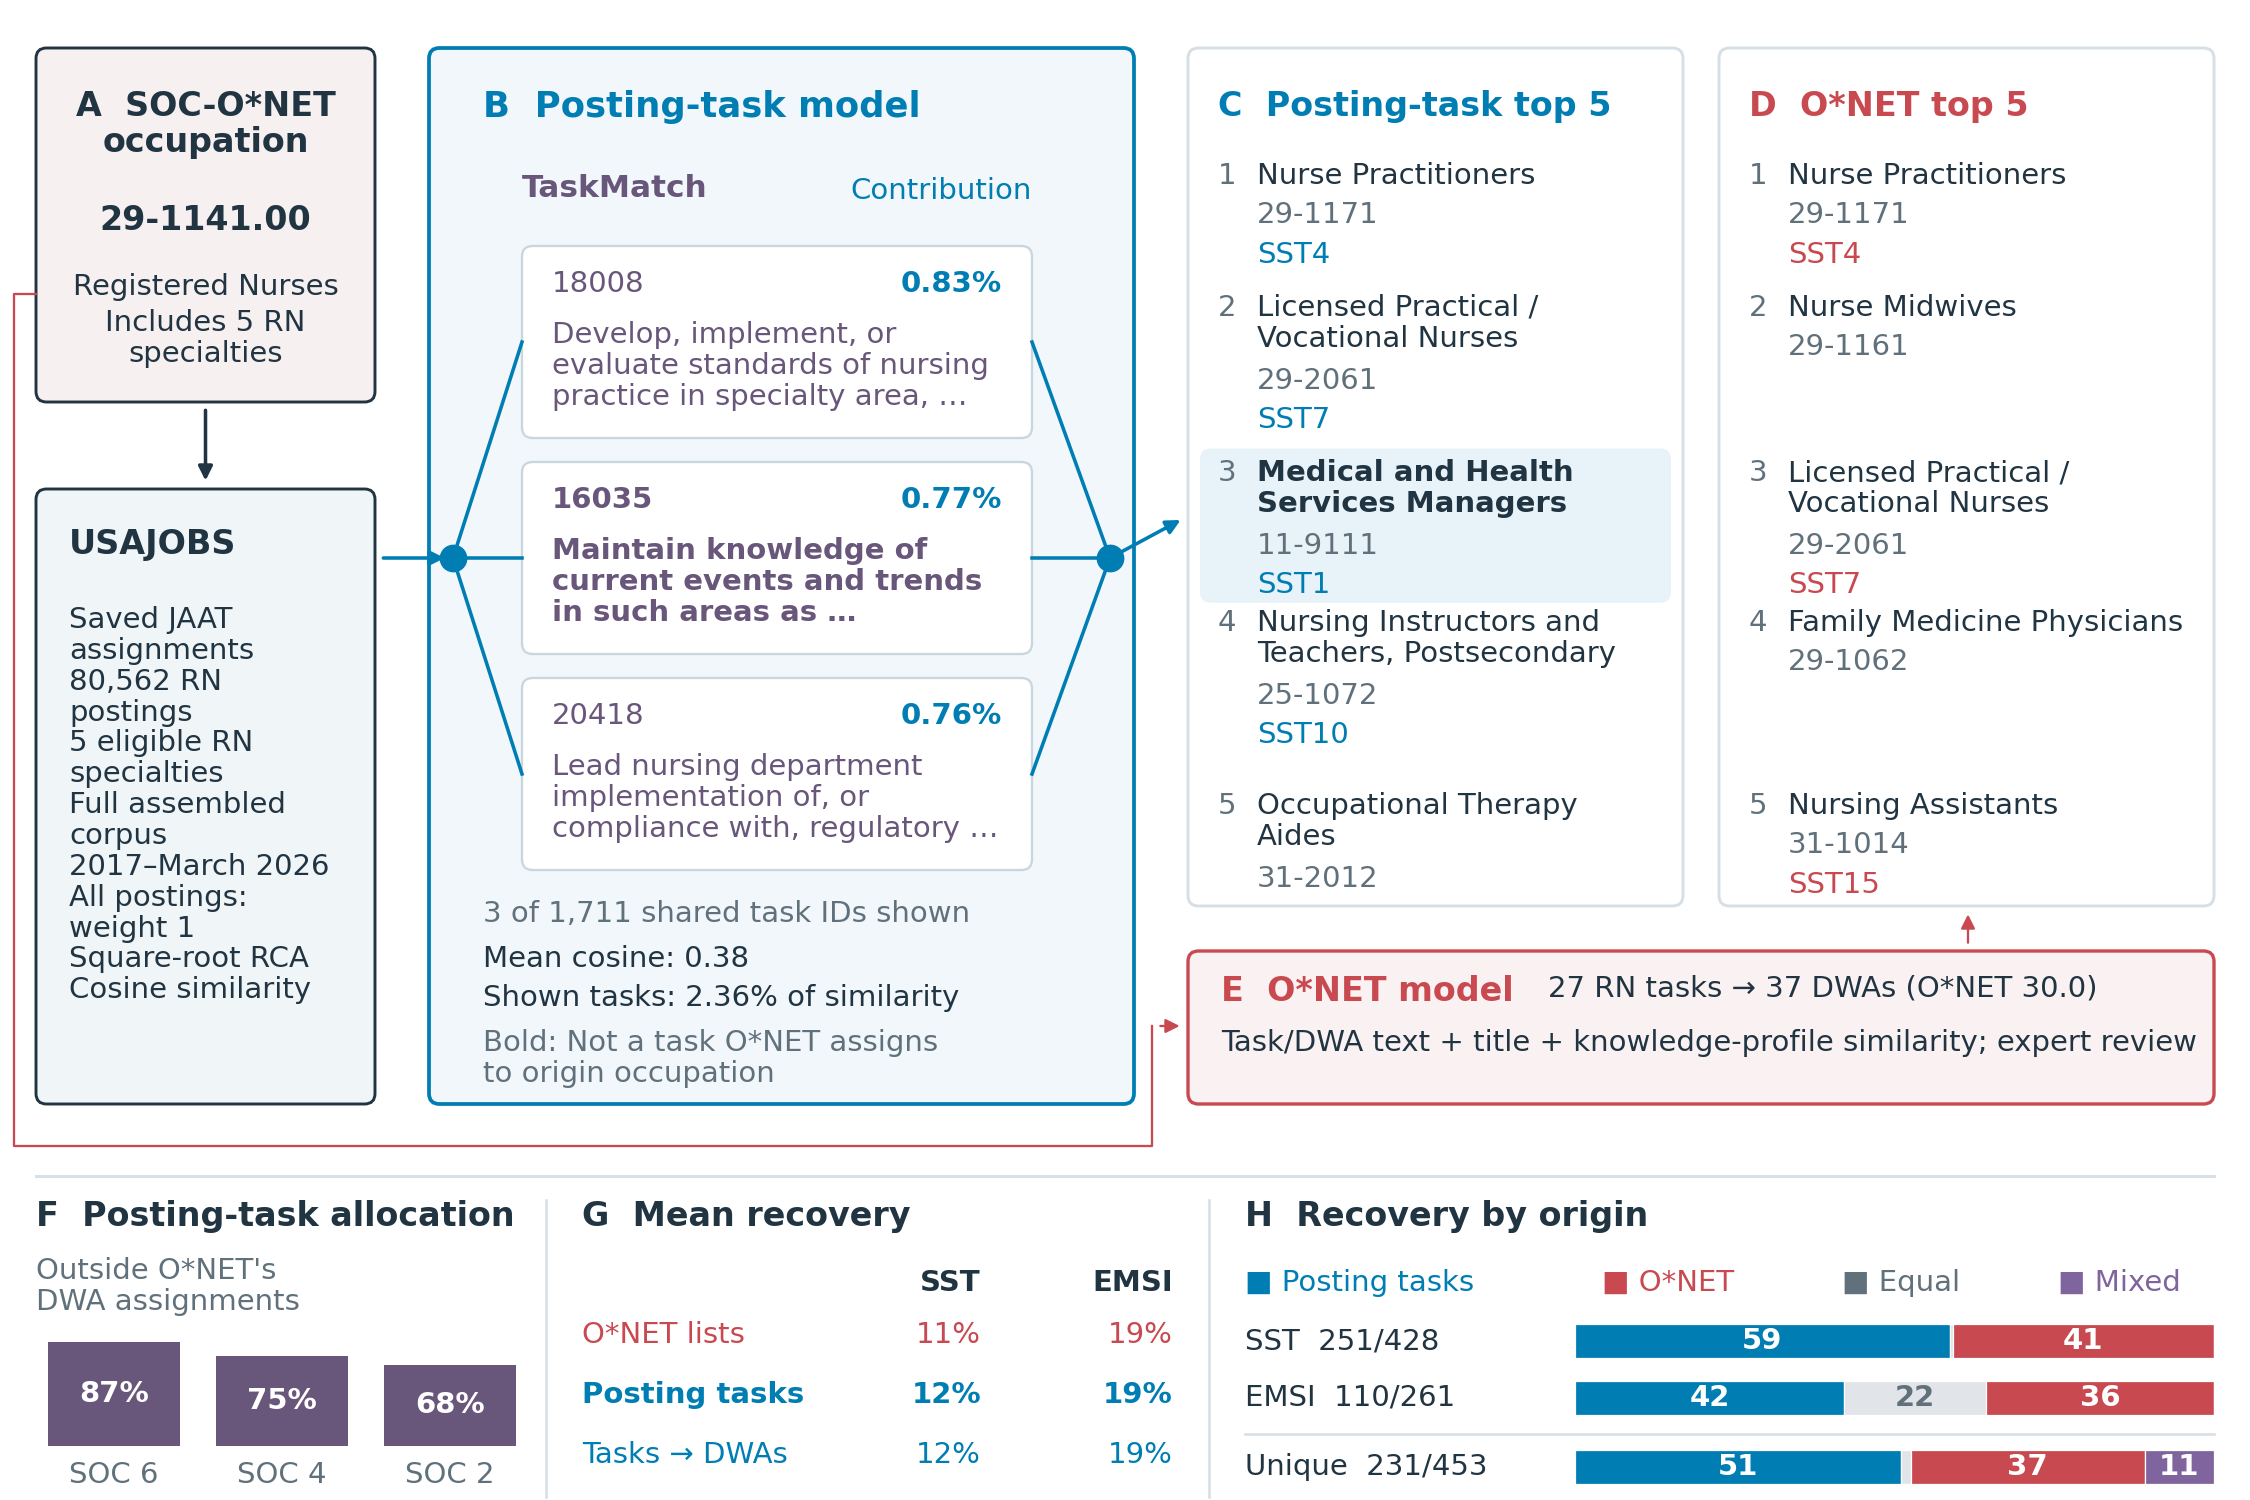

Saved PNG, SVG, PDF, benchmark tables, memberships, contributions and verification.


In [6]:
from usajobs_figure_rendering import render as render_usajobs
render_usajobs(c,OUT,'figure2_usajobs')
display(Image(filename=str(OUT/'figure2_usajobs.png')))
paper_case=read_figure_workbook(PAPER/'figure/registered_nurses_public.xlsx')
# Check the workbook's headline numbers against the independently rebuilt summaries.
workbook_summary=pd.DataFrame(paper_case['equal_length_summary'])
# The workbook also contains eight individual-survey sensitivities; this control
# reconstructs the six combined benchmarks distributed in benchmark_inputs.
workbook_summary=workbook_summary[workbook_summary.dataset.isin(paper_summary.dataset)]
assert len(workbook_summary)==6
for r in workbook_summary.itertuples():
    q=paper_summary[paper_summary.dataset.eq(r.dataset)&paper_summary['mode'].eq('equal_length')].iloc[0]
    for k in ['task','onet_published','share_more']: np.testing.assert_allclose(getattr(r,k),q[k],atol=1e-12)
render_paper(paper_case,OUT/'paper_control','figure2_paper_control')
report={'paper_rankings_and_summaries':'PASS','equal_length_counts':'PASS','shared_contributions_sum':'PASS',
 'usa_reference_stage':'retained','usa_reference_occupations':len(codes),'usa_eligible_specialties':len(eligible),
 'rn_manager_group_score':pair_score,'rn_specialties':groups[origin],'manager_specialties':groups[destination],
 'review':'NLx production pair exclusions applied; unreviewed links retained','coverage':coverage}
(OUT/'verification.json').write_text(json.dumps(report,indent=2))
print('Saved PNG, SVG, PDF, benchmark tables, memberships, contributions and verification.')